In [11]:
from parser import parse_chat
df = parse_chat("data/sample_chat.txt")

In [12]:
sender_order = df["sender"].value_counts().index
sender_map = {
    sender: f"User {rank}"
    for rank, sender in enumerate(sender_order, start=1)
}
df["sender"] = df["sender"].map(sender_map)
del sender_order, sender_map

In [13]:
print("Number of messages:", len(df))
print("Number of participants:", df["sender"].nunique())

Number of messages: 2000
Number of participants: 4


In [14]:
top_users = df["sender"].value_counts()

top_users

sender
User 1    720
User 2    560
User 3    430
User 4    290
Name: count, dtype: int64

This chart shows relative message volume by anonymized participant, highlighting who contributed most.

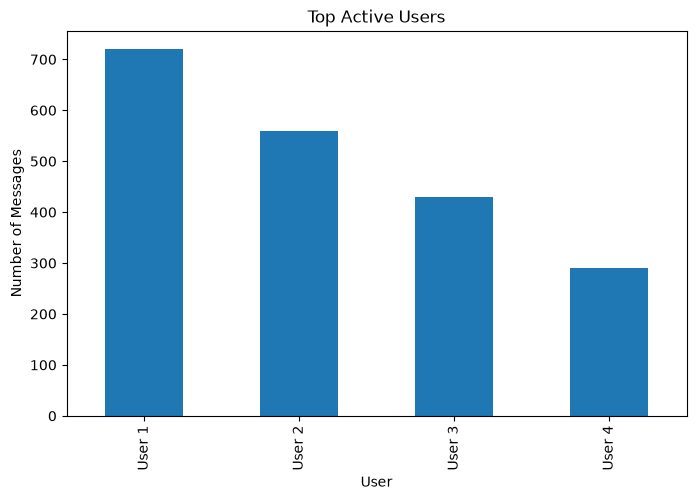

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
top_users.plot(kind="bar")

plt.title("Top Active Users")
plt.xlabel("User")
plt.ylabel("Number of Messages")

plt.show()

Ranked message counts make the relative participation gap between anonymized participants easy to compare.

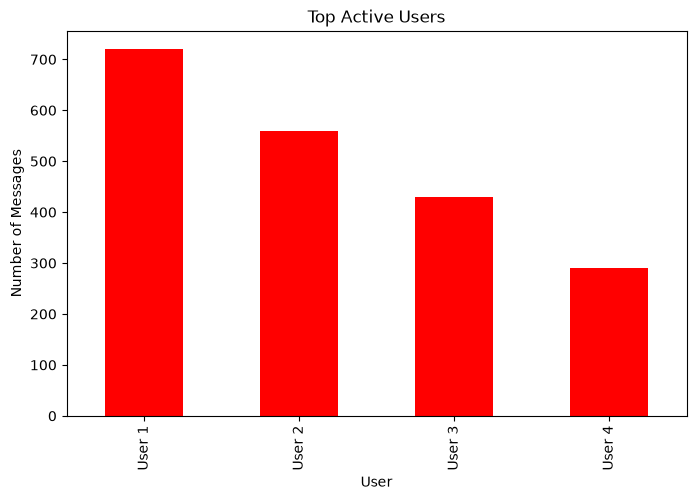

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

top_users.plot(
    kind="bar",
    color="red"
)

plt.title("Top Active Users")
plt.xlabel("User")
plt.ylabel("Number of Messages")

plt.show()

In [17]:
top_users = df["sender"].value_counts()
top_users

sender
User 1    720
User 2    560
User 3    430
User 4    290
Name: count, dtype: int64

In [18]:
df["datetime"] = pd.to_datetime(df["datetime"], format="%m/%d/%y, %I:%M %p")

df["hour"] = df["datetime"].dt.hour

hourly_messages = df["hour"].value_counts().sort_index()

hourly_messages

hour
0     101
1     103
2     101
5      33
6      28
7      36
8      32
9      65
10     76
11     68
12     59
13     72
14     71
15     73
16     68
17     79
18    156
19    143
20    147
21    167
22    147
23    175
Name: count, dtype: int64

In [19]:
print("Most active hour:", hourly_messages.idxmax())
print("Messages sent:", hourly_messages.max())

Most active hour: 23
Messages sent: 175


In [20]:
media_count = df["message"].str.contains(
    "<Media omitted>",
    na=False
).sum()

print("Number of media files:", media_count)

Number of media files: 300


In [21]:
media_percentage = (media_count / len(df)) * 100

print(f"Media percentage: {media_percentage:.2f}%")

Media percentage: 15.00%


In [22]:
df["datetime"] = pd.to_datetime(df["datetime"], format="%m/%d/%y, %I:%M %p")

df["day_name"] = df["datetime"].dt.day_name()

In [23]:
day_activity = df["day_name"].value_counts()

print(day_activity)

day_name
Friday       384
Wednesday    353
Monday       326
Thursday     260
Tuesday      242
Sunday       223
Saturday     212
Name: count, dtype: int64


In [24]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_activity = day_activity.reindex(days_order)

This comparison reveals which days of the week tend to have the most conversation activity.

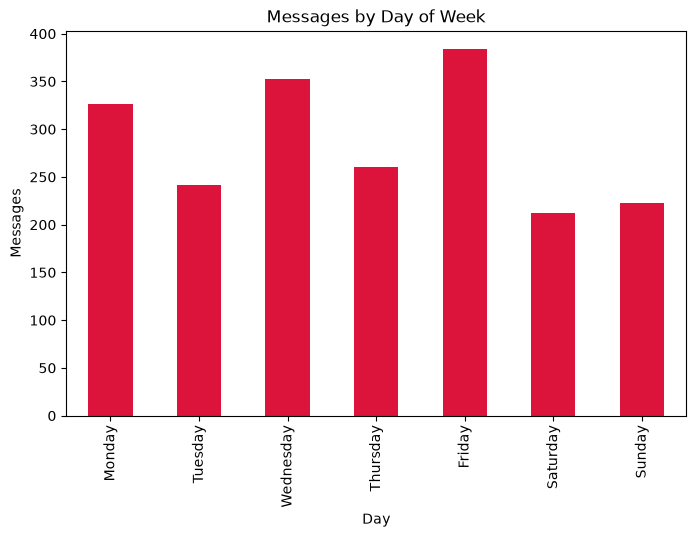

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

day_activity.plot(
    kind="bar",
    color="crimson"
)

plt.title("Messages by Day of Week")
plt.xlabel("Day")
plt.ylabel("Messages")

plt.show()

In [26]:
df["date"] = df["datetime"].dt.date

daily_messages = df.groupby("date").size()

daily_messages.head()

date
2026-05-01    57
2026-05-02    34
2026-05-03    46
2026-05-04    53
2026-05-05    40
dtype: int64

This timeline shows how message volume changes over the course of the conversation, including peaks and quieter periods.

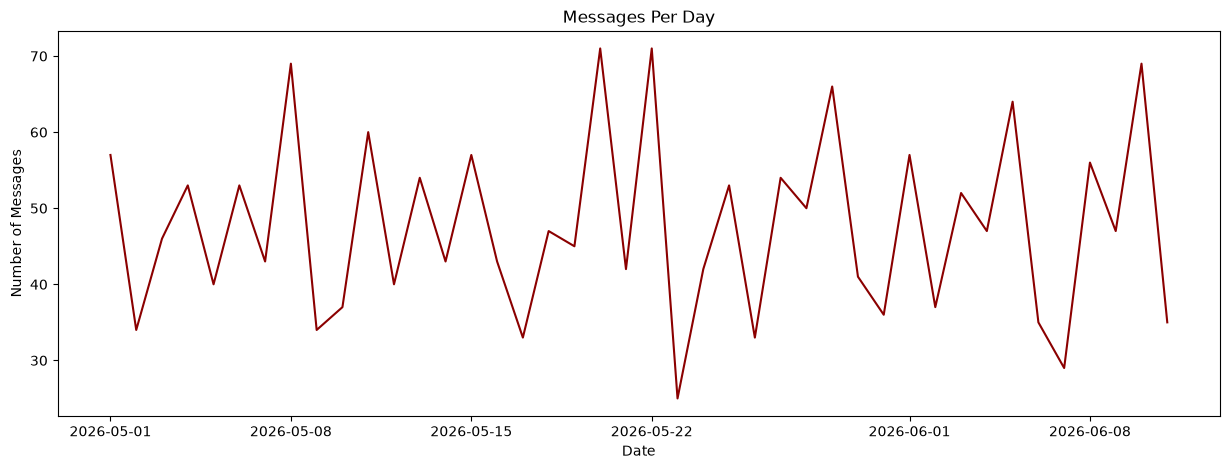

In [27]:
plt.figure(figsize=(15,5))

daily_messages.plot(
    color="darkred"
)

plt.title("Messages Per Day")
plt.xlabel("Date")
plt.ylabel("Number of Messages")

plt.show()

In [28]:
media_df = df[df["message"].str.contains("<Media omitted>", na=False)]

media_by_user = media_df["sender"].value_counts()

print(media_by_user)

sender
User 1    116
User 2     80
User 3     57
User 4     47
Name: count, dtype: int64


This chart compares media-sharing frequency across anonymized participants.

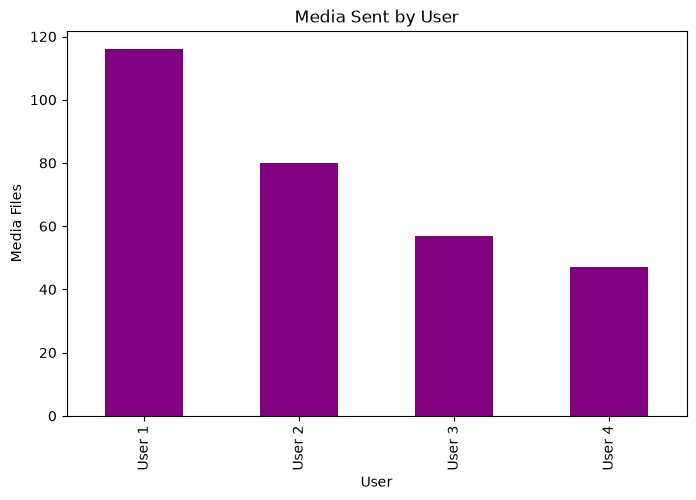

In [29]:
plt.figure(figsize=(8,5))

media_by_user.plot(
    kind="bar",
    color="purple"
)

plt.title("Media Sent by User")
plt.xlabel("User")
plt.ylabel("Media Files")

plt.show()

In [38]:
df["hour"] = df["datetime"].dt.hour
df["day_name"] = df["datetime"].dt.day_name()

In [39]:
heatmap_data = pd.crosstab(
    df["day_name"],
    df["hour"]
)

In [32]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

heatmap_data = heatmap_data.reindex(days_order)

This heatmap highlights the hours and days when conversation activity is concentrated.

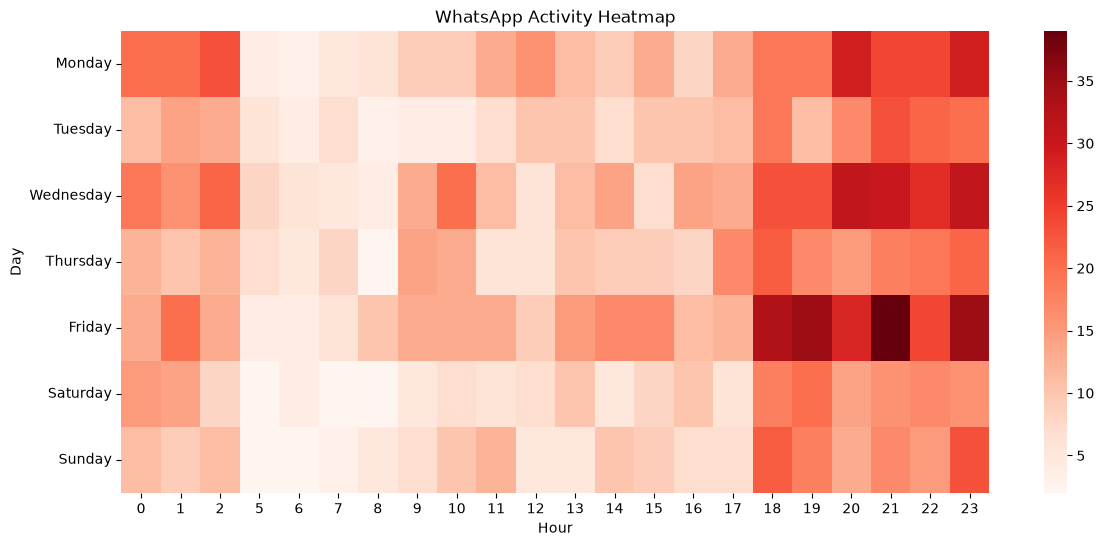

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="Reds"
)

plt.title("WhatsApp Activity Heatmap")
plt.xlabel("Hour")
plt.ylabel("Day")

plt.show()

In [34]:
messages = df["message"]

messages = messages[~messages.str.contains("<Media omitted>", na=False)]

text = " ".join(messages.astype(str))

In [35]:
from collections import Counter

words = text.split()

word_counts = Counter(words)

print(word_counts.most_common(20))

[('a', 220), ('That', 211), ("Let's", 195), ('خلينا', 117), ('بهدوء.', 117), ('was', 117), ('calm', 117), ('evening.', 117), ('Maybe', 117), ('after', 117), ('sunset.', 117), ("I'll", 117), ('check', 117), ('the', 117), ('timing.', 117), ('try', 116), ('another', 116), ('route.', 116), ('نبدأ', 114), ('نؤجلها', 113)]


In [36]:
stop_words = {"في","من","على","الى","إلى","و","يا","هو","هي","أنا","انا","ده","دي","دا","مع","عن","أن","إن"}

words = [
    word for word in text.split()
    if word not in stop_words and len(word) > 1
]

word_counts = Counter(words)

print(word_counts.most_common(15))

[('That', 211), ("Let's", 195), ('خلينا', 117), ('بهدوء.', 117), ('was', 117), ('calm', 117), ('evening.', 117), ('Maybe', 117), ('after', 117), ('sunset.', 117), ("I'll", 117), ('check', 117), ('the', 117), ('timing.', 117), ('try', 116)]


These frequent words summarize recurring topics, after filtering the configured stop words.

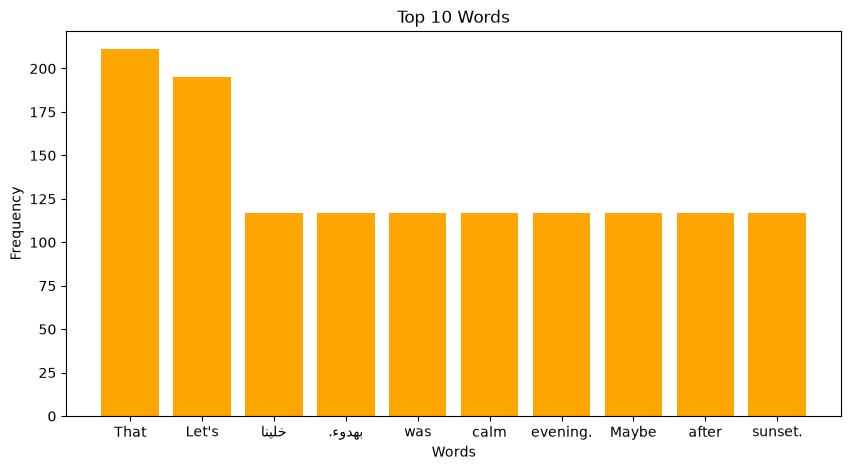

In [37]:
top_words = word_counts.most_common(10)

words = [w[0] for w in top_words]
counts = [w[1] for w in top_words]

plt.figure(figsize=(10,5))
plt.bar(words, counts, color="orange")

plt.title("Top 10 Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.show()